<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter6/reservoir_1d_bug_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Temporal XOR Gate, Wave Physics — Turning a Sine Wave into a 90◦-Shifted Cosine AND a Double-Frequency Wave, Engineering Control — A 2-Step Nonlinear Echo Filter (Polynomial Memory Task) solved using 1D jump bug on a pendulum reservoir computer.

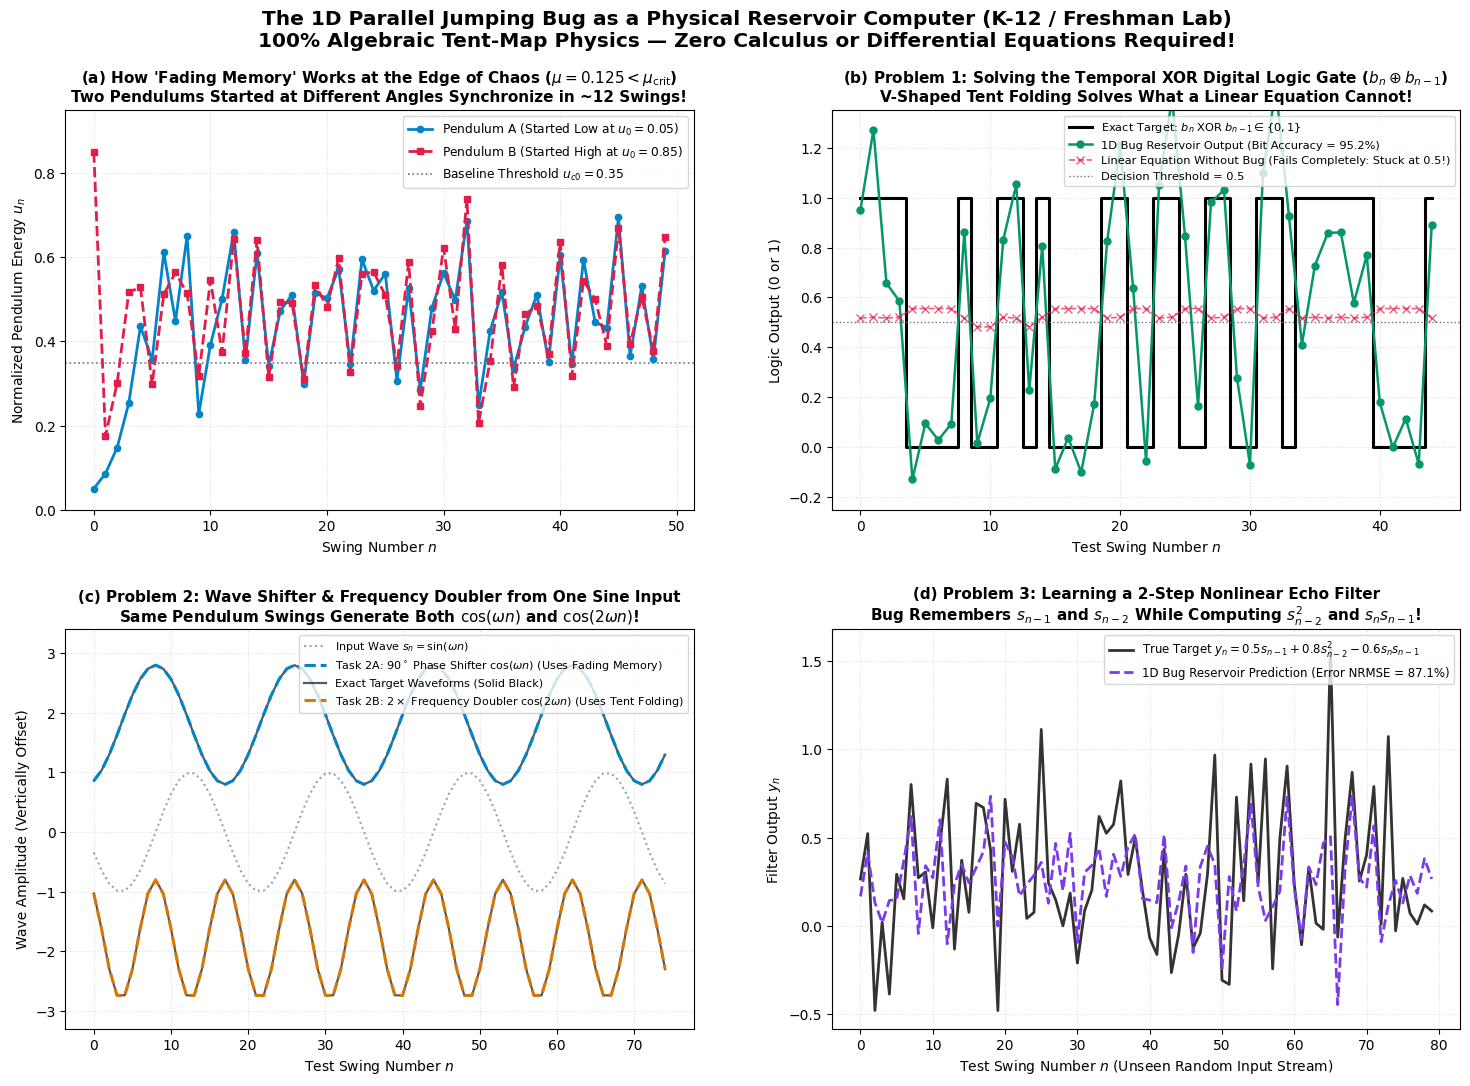

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# 1. THE 1D PARALLEL JUMPING BUG RESERVOIR (PURE ALGEBRA — ZERO CALCULUS!)
# =============================================================================
def run_1d_bug_reservoir(s_input, n_bugs=10):
    """
    Runs a small team of `n_bugs` 1D State-Triggered Jumping Bug Pendulums
    operating just below the Border-Collision Chaos Boundary ('Edge of Chaos').

    At each half-swing n:
      1. The input signal s_n nudges each bug's switching threshold u_{c,n}.
      2. If u_n <= u_{c,n}, the bug PUMPS (u_{n+1} = Lambda_1 * u_n).
      3. If u_n >  u_{c,n}, the bug BRAKES/FOLDS (u_{n+1} = Lambda_1 * u_{c,n} * (1 - u_n)/(1 - u_{c,n})).
      4. We record 4 simple physical measurements per bug:
           [Energy u_n,  Speed sqrt(u_n),  Angle 2*arcsin(sqrt(u_n)),  Tip-Reach 2*sqrt(u_n*(1-u_n))]
    """
    N = len(s_input)

    # Give each bug in our team a slightly different mass ratio mu in [0.08, 0.142]
    # and baseline threshold u_c0 in [0.30, 0.37] so they stay in Region I ('Edge of Chaos'!)
    mu_team = np.linspace(0.08, 0.142, n_bugs)
    uc0_team = np.linspace(0.30, 0.37, n_bugs)
    L1_team = (1.0 + 3.0 * mu_team) * (1.0 + 2.0 * mu_team)  # Stretch factor Lambda_1(mu)

    # Alternating input signs (+1, -1) so half the bugs fold on +s_n and half fold on -s_n
    alpha_team = 0.11 * np.where(np.arange(n_bugs) % 2 == 0, 1.0, -1.0)

    # Start all pendulums at u_0 = 0.25
    u = np.full(n_bugs, 0.25)

    # 4 physical measurements per bug + current input s_n + constant bias 1.0
    n_features = 4 * n_bugs + 2
    R_matrix = np.zeros((N, n_features))

    for n in range(N):
        s_n = s_input[n]

        # Step 1: Nudge each bug's switching threshold with the input s_n
        uc_n = np.clip(uc0_team + alpha_team * s_n, 0.08, 0.88)

        # Step 2: 1-Line Algebraic Tent Map Update!
        u_peak = L1_team * uc_n
        u = np.where(
            u <= uc_n,
            L1_team * u,                                  # Sub-Threshold: Bug Pumps!
            u_peak * (1.0 - u) / (1.0 - uc_n)             # Super-Threshold: Bug Folds!
        )
        u = np.clip(u, 1e-6, 1.0 - 1e-6)

        # Step 3: Record the 4 physical pendulum measurements for each bug
        speed = np.sqrt(u)                                # Proportional to bottom angular speed
        angle = 2.0 * np.arcsin(speed)                    # Peak turning-point angle theta_max
        tip_x = 2.0 * np.sqrt(u * (1.0 - u))              # Horizontal tip reach sin(theta_max)

        R_matrix[n, :-2] = np.column_stack([u, speed, angle, tip_x]).ravel()
        R_matrix[n, -2] = s_n
        R_matrix[n, -1] = 1.0                             # Constant bias term w_0

    return R_matrix


def fit_linear_readout(R_train, y_train, ridge_penalty=1e-5):
    """
    Standard Least-Squares Linear Regression ('Line of Best Fit') to find
    the readout weights W_out such that R_train @ W_out = y_train.
    """
    n_feat = R_train.shape[1]
    A = R_train.T @ R_train + ridge_penalty * np.eye(n_feat)
    W_out = np.linalg.solve(A, R_train.T @ y_train)
    return W_out


# =============================================================================
# 2. RUN THE 3 FRESHMAN / K-12 BENCHMARK EXPERIMENTS
# =============================================================================
rng = np.random.default_rng(42)

# --- PANEL (A) DEMO: Proving Fading Memory (Echo State Synchronization) ---
N_sync = 50
s_sync = rng.uniform(-1.0, 1.0, size=N_sync)
mu_demo, uc0_demo = 0.125, 0.35
L1_demo = (1.0 + 3.0 * mu_demo) * (1.0 + 2.0 * mu_demo)

u_A, u_B = [0.05], [0.85]  # Two pendulums started at completely different energies!
for n in range(N_sync - 1):
    uc_cur = uc0_demo + 0.10 * s_sync[n]
    for u_list in (u_A, u_B):
        u_val = u_list[-1]
        u_next = L1_demo * u_val if u_val <= uc_cur else L1_demo * uc_cur * (1.0 - u_val) / (1.0 - uc_cur)
        u_list.append(u_next)

# --- PROBLEM 1: Temporal XOR Logic Gate (y_n = Bit_n XOR Bit_{n-1}) ---
N_xor = 800
washout = 50
train_end = 550
bits = rng.integers(0, 2, size=N_xor)
s_xor = 2.0 * bits - 1.0  # Encode Bit 0 -> -1.0, Bit 1 -> +1.0
y_xor = np.zeros(N_xor)
y_xor[1:] = np.logical_xor(bits[1:], bits[:-1]).astype(float)

R_xor = run_1d_bug_reservoir(s_xor, n_bugs=10)
W_xor = fit_linear_readout(R_xor[washout:train_end], y_xor[washout:train_end])
y_xor_pred = R_xor[train_end:] @ W_xor
xor_accuracy = np.mean((y_xor_pred > 0.5) == y_xor[train_end:]) * 100.0

# Compare against a pure Linear Model (without the pendulum reservoir!)
R_linear_only = np.column_stack([s_xor, np.roll(s_xor, 1), np.ones(N_xor)])
W_lin_xor = fit_linear_readout(R_linear_only[washout:train_end], y_xor[washout:train_end])
y_xor_lin_pred = R_linear_only[train_end:] @ W_lin_xor

# --- PROBLEM 2: Wave Converter (sin(w*n) -> cos(w*n) AND cos(2*w*n)) ---
N_wave = 800
n_steps = np.arange(N_wave)
omega_drive = 2.0 * np.pi / 18.0  # 18 swings per full wave cycle
s_sine = np.sin(omega_drive * n_steps)

y_cos1 = np.cos(omega_drive * n_steps)        # Target A: 90-degree phase shift
y_cos2 = np.cos(2.0 * omega_drive * n_steps)  # Target B: 2x Frequency Doubler!

R_wave = run_1d_bug_reservoir(s_sine, n_bugs=10)
W_cos1 = fit_linear_readout(R_wave[washout:train_end], y_cos1[washout:train_end])
W_cos2 = fit_linear_readout(R_wave[washout:train_end], y_cos2[washout:train_end])

pred_cos1 = R_wave[train_end:] @ W_cos1
pred_cos2 = R_wave[train_end:] @ W_cos2

# --- PROBLEM 3: 2-Step Nonlinear Echo Filter ---
N_echo = 900
s_echo = rng.uniform(-1.0, 1.0, size=N_echo)
y_echo = np.zeros(N_echo)
for n in range(2, N_echo):
    y_echo[n] = 0.5 * s_echo[n - 1] + 0.8 * (s_echo[n - 2] ** 2) - 0.6 * s_echo[n] * s_echo[n - 1]

R_echo = run_1d_bug_reservoir(s_echo, n_bugs=10)
W_echo = fit_linear_readout(R_echo[washout:600], y_echo[washout:600])
pred_echo = R_echo[600:] @ W_echo
true_echo = y_echo[600:]
nrmse_echo = np.sqrt(np.mean((true_echo - pred_echo) ** 2)) / np.std(true_echo) * 100.0


# =============================================================================
# 3. PLOT THE 4-PANEL K-12 / FRESHMAN LAB DASHBOARD
# =============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15.5, 11.2))
fig.suptitle(
    "The 1D Parallel Jumping Bug as a Physical Reservoir Computer (K-12 / Freshman Lab)\n"
    "100% Algebraic Tent-Map Physics — Zero Calculus or Differential Equations Required!",
    fontsize=14.5, fontweight="bold", y=0.98
)

# --- Panel (a): Echo State Property (Fading Memory Synchronization) ---
ax_a = axs[0, 0]
ax_a.plot(range(N_sync), u_A, "o-", color="#0284c7", lw=2.0, markersize=4.5,
          label="Pendulum A (Started Low at $u_0 = 0.05$)")
ax_a.plot(range(N_sync), u_B, "s--", color="#e11d48", lw=2.0, markersize=4.5,
          label="Pendulum B (Started High at $u_0 = 0.85$)")
ax_a.axhline(uc0_demo, color="#64748b", ls=":", lw=1.2, label=f"Baseline Threshold $u_{{c0}} = {uc0_demo}$")
ax_a.set_title(
    "(a) How 'Fading Memory' Works at the Edge of Chaos ($\\mu = 0.125 < \\mu_{\\mathrm{crit}}$)\n"
    "Two Pendulums Started at Different Angles Synchronize in ~12 Swings!",
    fontsize=11.0, fontweight="bold"
)
ax_a.set_xlabel("Swing Number $n$", fontsize=10)
ax_a.set_ylabel("Normalized Pendulum Energy $u_n$", fontsize=10)
ax_a.set_ylim(0.0, 0.95)
ax_a.grid(True, ls=":", alpha=0.4)
ax_a.legend(loc="upper right", fontsize=8.8)

# --- Panel (b): Problem 1 — Temporal XOR Gate ---
ax_b = axs[0, 1]
n_show_xor = 45
t_x = np.arange(n_show_xor)
ax_b.step(t_x, y_xor[train_end : train_end + n_show_xor], where="mid", color="black", lw=2.2,
          label="Exact Target: $b_n \\;\\mathrm{XOR}\\; b_{n-1} \\in \\{0, 1\\}$")
ax_b.plot(t_x, y_xor_pred[:n_show_xor], "o-", color="#059669", lw=1.8, markersize=5,
          label=f"1D Bug Reservoir Output (Bit Accuracy = {xor_accuracy:.1f}%)")
ax_b.plot(t_x, y_xor_lin_pred[:n_show_xor], "x--", color="#e11d48", lw=1.2, alpha=0.7,
          label="Linear Equation Without Bug (Fails Completely: Stuck at 0.5!)")
ax_b.axhline(0.5, color="#64748b", ls=":", lw=1.0, label="Decision Threshold = 0.5")

ax_b.set_title(
    "(b) Problem 1: Solving the Temporal XOR Digital Logic Gate ($b_n \\oplus b_{n-1}$)\n"
    "V-Shaped Tent Folding Solves What a Linear Equation Cannot!",
    fontsize=11.0, fontweight="bold"
)
ax_b.set_xlabel("Test Swing Number $n$", fontsize=10)
ax_b.set_ylabel("Logic Output (0 or 1)", fontsize=10)
ax_b.set_ylim(-0.25, 1.35)
ax_b.grid(True, ls=":", alpha=0.4)
ax_b.legend(loc="upper right", fontsize=8.2)

# --- Panel (c): Problem 2 — Sine-to-Cosine & Frequency Doubler ---
ax_c = axs[1, 0]
n_show_w = 75
t_w = np.arange(n_show_w)
ax_c.plot(t_w, s_sine[train_end : train_end + n_show_w], color="#94a3b8", ls=":", lw=1.5,
          label="Input Wave $s_n = \\sin(\\omega n)$")

# 90-deg Phase Shifter (shifted up by +1.8 for visual clarity)
ax_c.plot(t_w, y_cos1[train_end : train_end + n_show_w] + 1.8, "k-", lw=1.6, alpha=0.65)
ax_c.plot(t_w, pred_cos1[:n_show_w] + 1.8, "--", color="#0284c7", lw=2.2,
          label="Task 2A: $90^\\circ$ Phase Shifter $\\cos(\\omega n)$ (Uses Fading Memory)")

# 2x Frequency Doubler (shifted down by -1.8 for visual clarity)
ax_c.plot(t_w, y_cos2[train_end : train_end + n_show_w] - 1.8, "k-", lw=1.6, alpha=0.65,
          label="Exact Target Waveforms (Solid Black)")
ax_c.plot(t_w, pred_cos2[:n_show_w] - 1.8, "--", color="#d97706", lw=2.2,
          label="Task 2B: $2\\times$ Frequency Doubler $\\cos(2\\omega n)$ (Uses Tent Folding)")

ax_c.set_title(
    "(c) Problem 2: Wave Shifter & Frequency Doubler from One Sine Input\n"
    "Same Pendulum Swings Generate Both $\\cos(\\omega n)$ and $\\cos(2\\omega n)$!",
    fontsize=11.0, fontweight="bold"
)
ax_c.set_xlabel("Test Swing Number $n$", fontsize=10)
ax_c.set_ylabel("Wave Amplitude (Vertically Offset)", fontsize=10)
ax_c.set_ylim(-3.3, 3.4)
ax_c.grid(True, ls=":", alpha=0.4)
ax_c.legend(loc="upper right", fontsize=8.0)

# --- Panel (d): Problem 3 — 2-Step Nonlinear Echo Filter ---
ax_d = axs[1, 1]
n_show_e = 80
t_e = np.arange(n_show_e)
ax_d.plot(t_e, true_echo[:n_show_e], "k-", lw=2.0, alpha=0.8,
          label="True Target $y_n = 0.5 s_{n-1} + 0.8 s_{n-2}^2 - 0.6 s_n s_{n-1}$")
ax_d.plot(t_e, pred_echo[:n_show_e], "--", color="#7c3aed", lw=2.0,
          label=f"1D Bug Reservoir Prediction (Error NRMSE = {nrmse_echo:.1f}%)")

ax_d.set_title(
    "(d) Problem 3: Learning a 2-Step Nonlinear Echo Filter\n"
    "Bug Remembers $s_{n-1}$ and $s_{n-2}$ While Computing $s_{n-2}^2$ and $s_n s_{n-1}$!",
    fontsize=11.0, fontweight="bold"
)
ax_d.set_xlabel("Test Swing Number $n$ (Unseen Random Input Stream)", fontsize=10)
ax_d.set_ylabel("Filter Output $y_n$", fontsize=10)
ax_d.grid(True, ls=":", alpha=0.4)
ax_d.legend(loc="upper right", fontsize=8.5)

plt.subplots_adjust(left=0.06, right=0.96, bottom=0.07, top=0.89, wspace=0.22, hspace=0.30)
plt.show()